In [1]:
import sys
# Remove any cached version of the module
for key in list(sys.modules.keys()):
    if 'LearnML' in key:
        del sys.modules[key]

In [2]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

# Verify path
print("Path added:", Path.cwd().parent)
#the previous lines is necessary to ensure that the LearnML library is correctly imported and used in the notebook, allowing for testing and experimentation with the regression models and their associated functions.

from LearnML.supervised.nb import NaiveBayes
from LearnML.selection.split import train_test_split
from LearnML.learn_about.learn_about import learn_about_NaiveBayes
from LearnML.metrics.metrics import classification_report



Path added: /home/mo/Documents/LearnML_Library


Gaussian Naive Bayes is a supervised classification algorithm based on Bayes' theorem. It assumes that the features are conditionally independent given the class and models each feature using a Gaussian (normal) distribution.

Key Concepts:
1. Classes: The model first finds all unique classes in the target y.
2. Class Separation: For each class, the training samples belonging to that class are selected.
3. Mean: For every feature, the model calculates the mean value for the current class.
4. Variance: For every feature, the model calculates the variance for the current class.
5. Prior: The model calculates how common each class is in the training data.
6. Gaussian PDF: During prediction, the mean and variance are used to calculate the likelihood of each feature.
7. Classification: The class with the highest posterior score is selected as the prediction.

Applications:
- Spam email classification
- Medical diagnosis classification
- Customer churn classification
- Document and text clas

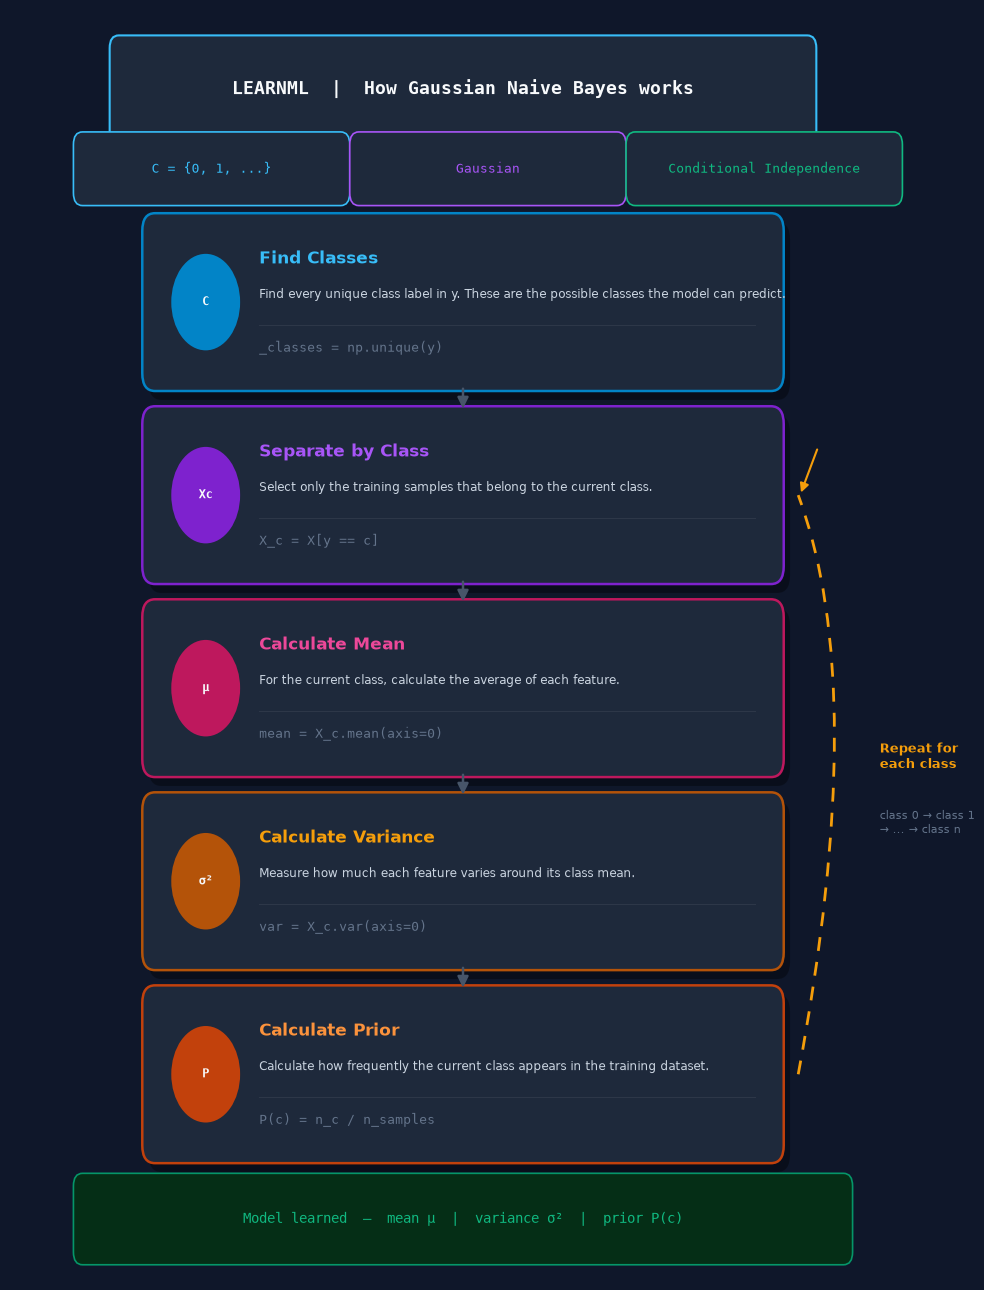

In [3]:
learn_about_NaiveBayes()

In [4]:
from sklearn.datasets import make_classification


##1. Generate synthetic classification data (70% informative features)
X, y = make_classification(
    n_samples=1000,         # Total number of rows/samples
    n_features=10,          # Total number of input features
    n_informative=7,        # 70% pure informative features (7 out of 10)
    n_redundant=2,          # 20% redundant features (linear combinations)
    # Note: Remaining 1 feature (10%) is automatically pure random noise
    n_classes=3,            # Number of target categories (e.g., 0, 1, 2)
    n_clusters_per_class=1, # Complexity of each class distribution
    weights=[0.5, 0.3, 0.2],# Class balance (50%, 30%, 20%)
    flip_y=0.02,            # Add 2% random label noise (set to 0.0 for 100% clean labels)
    random_state=42         # Seed for reproducible results
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



Text(0.5, 1.0, 'Training Data Distribution')

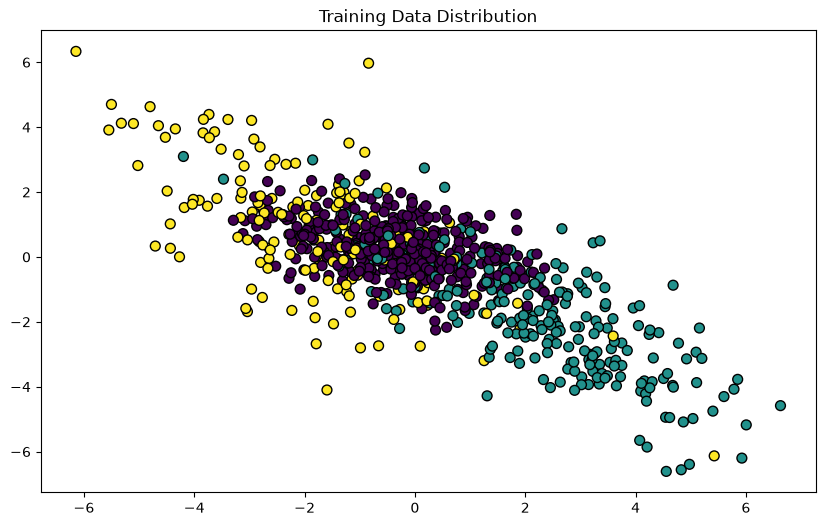

In [5]:
#visualize the data distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('Training Data Distribution')     

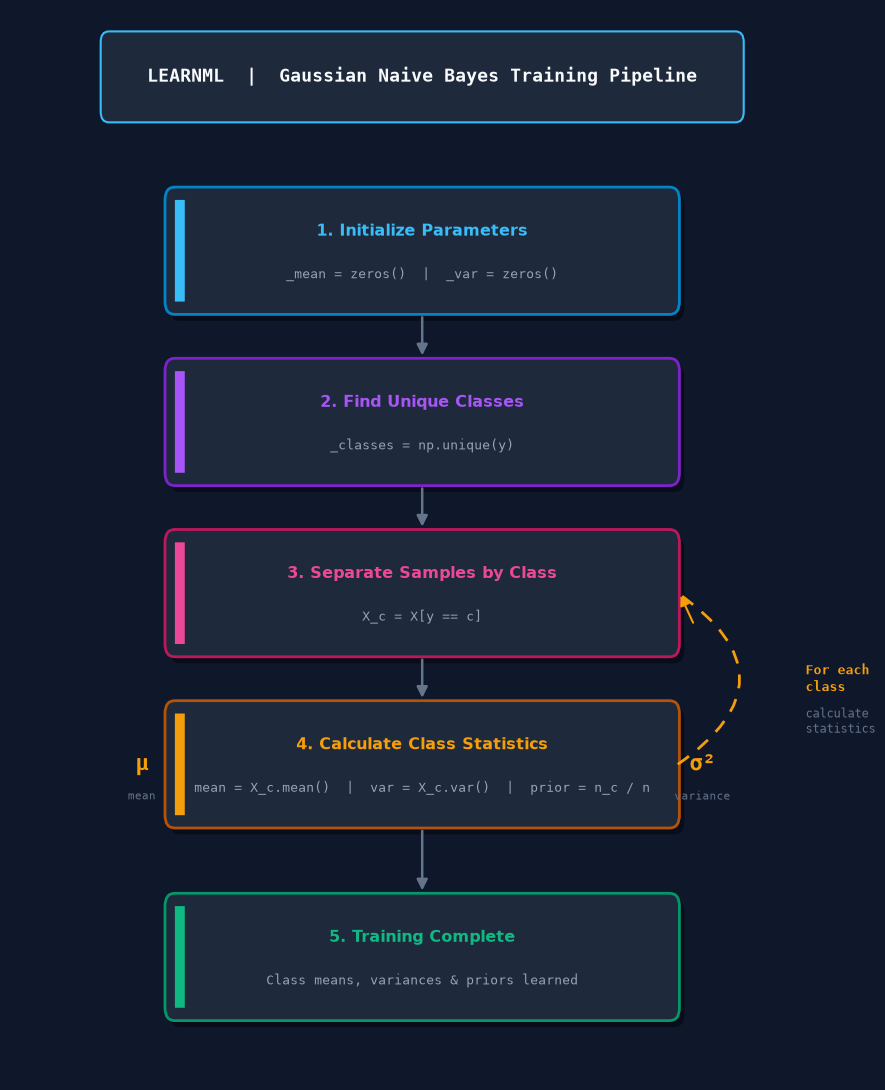

In [6]:
nb_model= NaiveBayes()
nb_model.fit(X_train, y_train)

In [7]:
predictions = nb_model.predict(X_test)
predictions

array([2, 0, 0, 0, 0, 2, 0, 2, 2, 0, 1, 2, 0, 0, 2, 0, 1, 0, 1, 0, 0, 0,
       2, 0, 1, 1, 0, 0, 0, 0, 0, 0, 2, 1, 1, 0, 1, 1, 2, 2, 0, 0, 0, 0,
       2, 0, 2, 0, 0, 2, 1, 1, 0, 1, 2, 0, 0, 0, 0, 0, 1, 1, 2, 1, 1, 0,
       1, 0, 0, 1, 0, 2, 0, 0, 1, 2, 0, 0, 1, 2, 0, 0, 2, 2, 1, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 1, 0, 0, 0, 2, 0, 1, 0, 1, 0,
       2, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 2, 1, 0, 0, 0, 0, 0, 2, 0, 1, 1, 1, 1, 2, 0, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 2, 0, 0, 2, 1, 0, 1, 1, 1, 0, 2, 2, 1, 2, 0, 0, 1, 0,
       2, 0, 0, 0, 0, 0, 2, 1, 0, 0, 1, 1, 0, 0, 0, 2, 1, 0, 2, 2, 0, 0,
       2, 2])

In [8]:
classification_report(y_test , predictions)

Accuracy: 0.86
Precision: 0.9583333333333334
Recall: 0.8363636363636363
F1 Score: 0.8932038834951457
